# 14 GRB 211211A from start to finish

The pipeline from notebooks 08-12, run on GRB 211211A, the other long burst from a merger with a precursor
(it is the grey burst in Dichiara's Fig. 2). Three aims: get its precursor and E_peak(t) to compare with
GRB 230307A, check them against the published analyses of this burst (Troja et al. 2022; Gompertz et al.
2023), and test that the code is general. Only the settings change: `settings_211211A.py` has the same names
as `settings.py`, and every function used here is the one used for GRB 230307A.

Data: TTE and CSPEC responses for n2, na and b0 (the detectors the GBM catalogue uses for this burst) and the
catalogue files, from the Fermi archive (HEASARC) with GDT's `TriggerFinder`.

In [1]:
import subprocess
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits

from gdt.core.binning.unbinned import bin_by_edges
from gdt.core.pha import Bak
from gdt.core.data_primitives import TimeBins
from gdt.core.spectra.functions import Band, Comptonized, BlackBody
from gdt.misc.bayesian_blocks import bayesian_blocks
from gdt.missions.fermi.gbm.tte import GbmTte

import settings_211211A as S
from lightcurve_tools import aligned_bin_edges, band_counts, fit_background, background_in_band, data_gaps, tte_path
from spectral_fit_tools import (make_spectra, window_response, write_rsp, rsp2_path, channel_mask, fit_model,
                                scaled_starts, cstat, covariance, profile_error, flux_with_error, energy_flux,
                                BandLowBreak)

pd.set_option("display.width", 200)
OUT_DIR = S.CODE_DIR / "spectra" / "time_resolved_211211A"
OUT_DIR.mkdir(exist_ok=True)

for det in S.SPECTRAL_DETECTORS:
    with fits.open(tte_path(S.DATA_DIR, S.BURST_ID, det)) as h:
        hdr = h[0].header
        print(f"{det}: {hdr['CREATOR'].split(' (')[0]}, {hdr['DATE']}, {h[2].header['NAXIS2']} events, "
              f"{hdr['TSTART'] - hdr['TRIGTIME']:.1f} to {hdr['TSTOP'] - hdr['TRIGTIME']:.1f} s")

n2: MakeTriggerTte v1.5.24, 2021-12-11T16:36:22, 1069865 events, -132.3 to 482.1 s
na: MakeTriggerTte v1.5.24, 2021-12-11T16:36:22, 1024138 events, -132.3 to 482.1 s
b0: MakeTriggerTte v1.5.24, 2021-12-11T16:36:22, 1221080 events, -132.3 to 482.1 s


Where the burst is relative to these detectors, from the headers of the responses (the angle between each
detector's axis and the burst, for the position in the catalogue file).

In [2]:
with fits.open(S.DATA_DIR / f"glg_tcat_all_{S.BURST_ID}_v01.fit") as h:
    print(f"position: RA {h[0].header['RA_OBJ']}, Dec {h[0].header['DEC_OBJ']} ({h[0].header['LOC_SRC']})")
for det in S.SPECTRAL_DETECTORS:
    with fits.open(rsp2_path(S.DATA_DIR, S.BURST_ID, det)) as h:
        trigger = h[0].header["TRIGTIME"]
        drms = [(e.header["TSTART"] - trigger, e.header["TSTOP"] - trigger, e.header["DET_ANG"]) for e in h[2:]]
    used = [angle for t0, t1, angle in drms if t1 > -1.0 and t0 < 80.0]
    print(f"{det}: {used[0]:.1f} deg from the burst at T0, {min(used):.1f}-{max(used):.1f} deg over the first 80 s")

position: RA 212.272, Dec 27.884 (Swift, BAT)
n2: 30.1 deg from the burst at T0, 26.2-30.1 deg over the first 80 s
na: 49.5 deg from the burst at T0, 49.5-50.7 deg over the first 80 s
b0: 79.4 deg from the burst at T0, 76.8-79.4 deg over the first 80 s


All three detectors face the burst: n2 is 30 deg off axis, na 50 deg and b0 79 deg at T0, and the angles change by at
most 4 deg over the first 80 s. Both NaI detectors are within 60 deg of the burst, so unlike GRB 230307A (notebook 08)
two detectors cover the low energies.

## 1. Light curve and background

The whole TTE range in 4 s bins with the background windows shaded. Cubic per channel, as for GRB 230307A.
Check: reduced chi2 near 1, and the background-subtracted counts average zero before the burst.

n2: background reduced chi2 0.962


na: background reduced chi2 0.968
   n2+na 8-1000 keV: net rate before -10 s averages -69.1 counts/s (scatter of the mean 53.3)
   n2+na 8-1000 keV: in the 41 s before T0 it averages -82.4 counts/s (scatter of the mean 19.1), -3.2% of the background


b0: background reduced chi2 0.929
   b0 200-40000 keV: net rate before -10 s averages -48.3 counts/s (scatter of the mean 37.7)
   b0 200-40000 keV: in the 41 s before T0 it averages -11.1 counts/s (scatter of the mean 4.6), -0.6% of the background


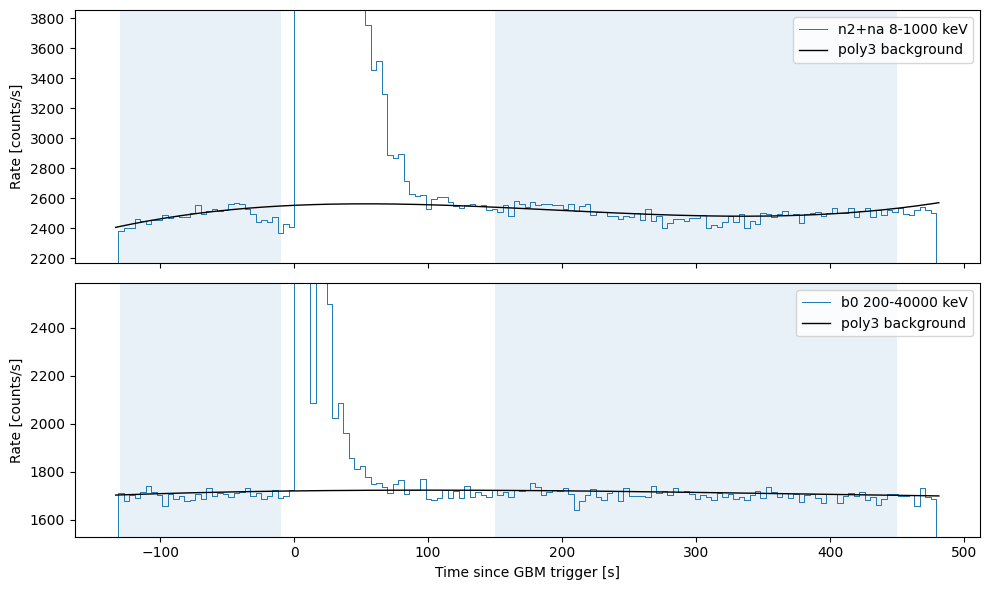

In [3]:
edges = aligned_bin_edges((-132.0, 480.0), 4.096)
centres = 0.5 * (edges[:-1] + edges[1:])
bkg_fits = {}
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, dets, band, name in ((axes[0], S.SOFT_DETECTORS, (8.0, 1000.0), "n2+na 8-1000 keV"),
                             (axes[1], ["b0"], (200.0, 40000.0), "b0 200-40000 keV")):
    raw = sum(band_counts(S.DATA_DIR, S.BURST_ID, d, band, edges) for d in dets) / 4.096
    model = 0
    for d in dets:
        bkg_fits[d], chi2 = fit_background(S.DATA_DIR, S.BURST_ID, d, S.BKG_WINDOWS, S.BKG_ORDER)
        model = model + background_in_band(bkg_fits[d], band, edges)[0] / 4.096
        print(f"{d}: background reduced chi2 {chi2:.3f}")
    ax.step(centres, raw, where="mid", lw=0.7, label=name)
    ax.plot(centres, model, color="black", lw=1, label=f"poly{S.BKG_ORDER} background")
    for lo, hi in S.BKG_WINDOWS:
        ax.axvspan(lo, hi, color="tab:blue", alpha=0.1, lw=0)
    ax.set_ylim(0.9 * model.min(), 1.5 * model.max())
    ax.set_ylabel("Rate [counts/s]")
    ax.legend(loc="upper right")
    pre = centres < -10
    print(f"   {name}: net rate before -10 s averages {np.mean(raw[pre] - model[pre]):+.1f} counts/s "
          f"(scatter of the mean {np.std(raw[pre] - model[pre]) / np.sqrt(pre.sum()):.1f})")
    late = (centres > -41) & (centres < 0)
    print(f"   {name}: in the 41 s before T0 it averages {np.mean(raw[late] - model[late]):+.1f} counts/s "
          f"(scatter of the mean {np.std(raw[late] - model[late]) / np.sqrt(late.sum()):.1f}), "
          f"{100 * np.mean(raw[late] - model[late]) / np.mean(model[late]):+.1f}% of the background")
axes[1].set_xlabel("Time since GBM trigger [s]")
fig.tight_layout()
fig.savefig(S.FIGURE_DIR / "14_211211a_background.png", dpi=200)
plt.show()

The fits are fine (reduced chi2 0.93-0.97) and the burst's tail is back on the cubic by ~100 s. Before -10 s the
net rate averages zero within its scatter. Right before the trigger, though, n2+na sit 82 +/- 19 counts/s (3.2%)
below the cubic over 41 s, a 4 sigma dip the polynomial can't follow; b0 is 0.6% low (2.4 sigma). It barely matters for
the bright windows, but the precursor is faint and starts at T0, so its fits are repeated with a local
background in section 4.

## 2. Precursor and windows

The precursor's edges come from Bayesian blocks (Scargle et al. 2013, GDT's binned version) on the light curve
of n2+na at 8-1000 keV, with an edge on T0 as for GRB 230307A (notebook 12, section 15), rather than by eye.
The precursor is the first run of blocks above the pre-burst rate, and the main emission starts at the next
block above it after that. 16 ms bins with a false-positive rate of 5% are the main choice; 1%, and 8 and
32 ms bins, check it.

In [4]:
def precursor_blocks(bin_width=0.016, p0=0.05):
    edges = np.round(aligned_bin_edges((-1.0, 1.6), bin_width), 6)
    counts, exposure = 0, 0
    for d in S.SOFT_DETECTORS:
        tte = GbmTte.open(tte_path(S.DATA_DIR, S.BURST_ID, d))
        lc = tte.slice_energy((8.0, 1000.0)).to_phaii(bin_by_edges, edges).to_lightcurve()
        tte.close()
        counts, exposure = counts + lc.counts, exposure + lc.exposure / len(S.SOFT_DETECTORS)
    cp = bayesian_blocks(TimeBins(counts, edges[:-1], edges[1:], exposure), p0=p0)
    return pd.DataFrame({"start": edges[cp[:-1]], "stop": edges[cp[1:]],
                         "rate": [counts[a:b].sum() / exposure[a:b].sum() for a, b in zip(cp[:-1], cp[1:])]})

def precursor_edges(blocks):
    background_rate = blocks.rate.iloc[0]
    above = (blocks.rate > 1.1 * background_rate).values
    first = int(np.argmax(above))
    last = first
    while above[last + 1]:
        last += 1
    main = last + 1
    while not above[main]:
        main += 1
    gap = blocks.iloc[last + 1:main]
    return dict(start=blocks.start[first], stop=blocks.stop[last], main_start=blocks.start[main],
                gap_over_pre_burst=gap.rate.max() / background_rate, pre_burst_rate=background_rate)

blocks = precursor_blocks()
check = pd.DataFrame({f"{1e3 * w:.0f} ms, p0 {p0}": precursor_edges(precursor_blocks(w, p0))
                      for w, p0 in ((0.016, 0.05), (0.016, 0.01), (0.008, 0.05), (0.032, 0.05))}).T
print(check.round(3).to_string())
edges_16 = precursor_edges(blocks)
PRECURSOR = (float(edges_16["start"]), float(edges_16["stop"]))
MAIN_START = float(edges_16["main_start"])
blocks.round(3)

                start   stop  main_start  gap_over_pre_burst  pre_burst_rate
16 ms, p0 0.05 -0.016  0.432       1.104               1.017        2400.120
16 ms, p0 0.01 -0.016  0.224       1.104               1.057        2400.120
8 ms, p0 0.05  -0.024  0.408       1.096               1.022        2386.997
32 ms, p0 0.05 -0.032  0.224       1.088               1.063        2383.887


,start,stop,rate
0,-1.008,-0.016,2400.120
1,-0.016,0.048,12839.439
2,0.048,0.144,7140.776
3,0.144,0.192,4716.971
4,0.192,0.432,2941.092
5,0.432,1.104,2441.376
6,1.104,1.360,3879.850
7,1.360,1.536,6500.087
8,1.536,1.584,11013.821
9,1.584,1.600,15385.106


The precursor starts at -0.016 s (-0.024 and -0.032 s with 8 and 32 ms bins) and the main emission at 1.104 s
(1.088-1.104 s in all four versions). In between the rate is back at the pre-burst level (2% above it with 16 ms
and 5%, at most 6% above in the other versions), so unlike GRB 230307A this precursor is separated from the
main emission by a quiet gap of 0.7-0.9 s, as Troja et al. (2022) describe. Where the precursor ends is less
clear-cut: its last block (0.192-0.432 s) is a faint tail at 1.2 times the pre-burst rate, which a 1%
false-positive rate or 32 ms bins merge into the gap, ending the precursor at 0.224 s instead. I keep the
16 ms, 5% version, -0.016 to 0.432 s, which includes the tail.

For the rest of the burst I use the time slices of Gompertz et al. (2023), who fitted the GBM data of the same
three detectors (with Swift/BAT) in 2 s slices up to 26 s, then 4 s to 50 s and 10 s to 70 s, merging the quiet
12-16 s into one. Their times are from the BAT trigger, 13:09:59.60 UT, and the GBM trigger is 0.05 s later
(13:09:59.651 UT), so I use their edges unchanged; 0.05 s is small next to the slices. With the same windows
their E_peak can be compared slice by slice (section 7). Two more windows copy the grey bars of GRB 211211A in
Dichiara's Fig. 2, 1-10 s and 27-66 s, with edges read off the figure. Everything goes into
`shared/windows_211211A.csv`, same format as for GRB 230307A.

In [5]:
G_EDGES = [0, 2, 4, 6, 8, 10, 12, 16, 18, 20, 22, 24, 26, 30, 34, 38, 42, 46, 50, 60, 70]
rows = [("pre", *PRECURSOR, "Bayesian blocks")]
rows += [(f"g{a:02d}_{b:02d}", float(a), float(b), "Gompertz et al. (2023) slice") for a, b in zip(G_EDGES[:-1], G_EDGES[1:])]
rows += [("f2_01_10", 1.0, 10.0, "Dichiara Fig. 2, read off"), ("f2_27_66", 27.0, 66.0, "Dichiara Fig. 2, read off")]
windows = pd.DataFrame(rows, columns=["label", "t_start", "t_stop", "source"]).set_index("label")
with open(S.WINDOWS_FILE, "w") as f:
    f.write(f"# GRB 211211A, Fermi/GBM trigger {S.BURST_ID}. T0 = {S.TRIGGER_MET} s MET (GBM trigger time).\n"
            "# Times in s from T0. Precursor edges from Bayesian blocks; g windows are the slices of Gompertz et al.\n"
            "# (2023); f2 windows have edges read off Dichiara et al. (2023) Fig. 2 (notebook 14).\n")
    windows.to_csv(f)
WIN = {label: (row.t_start, row.t_stop) for label, row in windows.iterrows()}
print(f"{len(WIN)} windows; main emission starts at {MAIN_START} s")
windows

23 windows; main emission starts at 1.104 s


,t_start,t_stop,source
label,,,
pre,-0.016,0.432,Bayesian blocks
g00_02,0.000,2.000,Gompertz et al. (2023) slice
g02_04,2.000,4.000,Gompertz et al. (2023) slice
g04_06,4.000,6.000,Gompertz et al. (2023) slice
g06_08,6.000,8.000,Gompertz et al. (2023) slice
g08_10,8.000,10.000,Gompertz et al. (2023) slice
g10_12,10.000,12.000,Gompertz et al. (2023) slice
g12_16,12.000,16.000,Gompertz et al. (2023) slice
g16_18,16.000,18.000,Gompertz et al. (2023) slice


## 3. Spectra, responses and checks

Same functions as notebook 12. Windows that cross a boundary between response matrices get the
counts-weighted response.

In [6]:
spectra, responses, response_type = {}, {}, {}
for det in S.SPECTRAL_DETECTORS:
    spectra[det], _ = make_spectra(S.DATA_DIR, S.BURST_ID, det, WIN, S.BKG_WINDOWS, S.BKG_ORDER)
    for label, window in WIN.items():
        responses[det, label], response_type[det, label] = window_response(S.DATA_DIR, S.BURST_ID, det, window)
        pha, bkg = spectra[det][label]
        stem = f"{S.BURST_ID}_{det}_{label}"
        pha.write(OUT_DIR, filename=stem + ".pha", overwrite=True)
        Bak.from_data(bkg, gti=pha.gti, trigger_time=pha.trigtime).write(OUT_DIR, filename=stem + ".bak", rates=True,
                                                                          overwrite=True)
        write_rsp(responses[det, label], OUT_DIR, stem + ".rsp")

rows = []
for label, (t0, t1) in WIN.items():
    for det in S.SPECTRAL_DETECTORS:
        pha, bkg = spectra[det][label]
        total, background = float(np.sum(pha.data.counts)), float(np.sum(bkg.counts))
        rows.append(dict(label=label, detector=det, live_fraction=pha.exposure / (t1 - t0),
                         bkg_fraction=background / total, net=total - background,
                         snr=(total - background) / np.sqrt(total + np.sum(bkg.count_uncertainty**2))))
checks = pd.DataFrame(rows)
summary = checks.groupby("label", sort=False).agg(min_live_fraction=("live_fraction", "min"),
                                                  max_bkg_fraction=("bkg_fraction", "max"),
                                                  net_counts=("net", "sum"))
for det in S.SPECTRAL_DETECTORS:
    summary[f"snr_{det}"] = checks[checks.detector == det].set_index("label").snr
summary["response"] = [response_type["n2", l] for l in summary.index]
gap_count = sum(len(data_gaps(S.DATA_DIR, S.BURST_ID, d, (-1.0, 90.0))[0]) for d in S.SPECTRAL_DETECTORS)
print("data gaps in -1 to 90 s, all detectors:", gap_count)
summary.round(3)

data gaps in -1 to 90 s, all detectors: 0


,min_live_fraction,max_bkg_fraction,net_counts,snr_n2,snr_na,snr_b0,response
label,,,,,,,
pre,0.992,0.972,1308.668,20.881,15.623,0.796,single DRM
g00_02,0.990,0.636,10256.420,56.212,42.676,27.283,single DRM
g02_04,0.957,0.175,69692.580,167.038,142.265,117.576,single DRM
g04_06,0.964,0.260,52778.238,149.686,124.449,86.741,single DRM
g06_08,0.921,0.088,135398.495,232.802,200.835,181.209,single DRM
g08_10,0.966,0.261,51037.210,145.792,122.300,86.463,single DRM
g10_12,0.980,0.553,24488.749,103.135,81.761,35.946,single DRM
g12_16,0.991,0.834,15700.998,72.261,53.735,15.071,single DRM
g16_18,0.983,0.596,20076.372,91.899,71.466,31.308,single DRM


No data gaps, and the dead time is at most 8% (6-8 s, the brightest slice), so neither needs the care it did
for GRB 230307A. Every Gompertz slice has S/N of at least 24 in both NaI detectors, and the precursor 21 in n2
and 16 in na. b0 sees the main emission well, but not the precursor (S/N 0.8) and only weakly after 42 s
(S/N 2-6), where it mostly limits the high-energy tail. 18-20 s, 60-70 s and 27-66 s cross response boundaries
(19.22 and 64.27 s) and get counts-weighted responses.

## 4. Fits

Band, Comptonized and the two-break model from notebook 12 (`BandLowBreak`) in every window, with the same
starting grids and polishing. Which one gives the E_peak for a window, with the same thresholds as in
notebook 12:
- The two-break model, where its fit is clean (break inside the fitted range and below half the peak, slopes
  not at their limits, beta below -2) and clearly better than Band: Delta C > 11.8, 3 sigma for two extra parameters. When
  the spectrum has a second break, Band puts its E_peak somewhere between the two, below the nuFnu peak.
- Otherwise Band, if its high-energy tail is needed (Delta C > 9 over Comptonized) and beta isn't at GDT's limit of
  -2, where the nuFnu spectrum doesn't turn down above the "peak" and Band's E_peak is a break, not a peak.
- Otherwise the Comptonized E_peak.

This is a different choice from GRB 230307A, where I kept Band everywhere to compare with Dichiara and gave
the alternatives next to it (notebook 12, sections 11 and 12). Errors on E_peak are from the profile
likelihood of the model used, the others from its covariance matrix.

In [7]:
GRID = [[1.0, e, a, b, 100.0] for e in (100.0, 300.0, 900.0) for a in (-0.6, -1.2) for b in (-2.6, -4.0, -6.0)]
CPL_GRID = [[1.0, e, a, 100.0] for e in (100.0, 300.0, 900.0) for a in (-0.6, -1.2)]

def window_data(label):
    phas = [spectra[d][label][0] for d in S.SPECTRAL_DETECTORS]
    baks = [spectra[d][label][1] for d in S.SPECTRAL_DETECTORS]
    rsps = [responses[d, label] for d in S.SPECTRAL_DETECTORS]
    masks = [channel_mask(r, S.FIT_RANGE_BGO if d.startswith("b") else S.FIT_RANGE_NAI)
             for r, d in zip(rsps, S.SPECTRAL_DETECTORS)]
    return phas, baks, rsps, masks

def lowbreak_shapes(epeak):
    return [[1.0, eb, a1, a2, ep, b, 2.0, 100.0] for eb in (20.0, 50.0, 100.0) for a1 in (-0.4, -0.7)
            for a2 in (-1.2, -1.5) for ep in (epeak, 2 * epeak) for b in (-2.5, -3.5)]

def cov_errors(fit):
    try:
        with np.errstate(invalid="ignore"):
            return np.sqrt(np.diag(covariance(fit)))
    except np.linalg.LinAlgError:
        return np.full(len(fit.parameters), np.nan)

rows, fits_ = [], {}
for label in WIN:
    data = window_data(label)
    band = Band()
    band_fit = fit_model(*data, band, scaled_starts(band, *data, GRID), polish=True)
    cpl = Comptonized()
    cpl_fit = fit_model(*data, cpl, scaled_starts(cpl, *data, CPL_GRID) + [list(band.default_values[:3]) + [100.0]],
                        polish=True)
    lb = BandLowBreak()
    A, epk, al, be = band_fit.parameters
    lb_starts = scaled_starts(lb, *data, lowbreak_shapes(cpl_fit.parameters[1]))
    lb_starts.append([A, 2.0, al, al, epk, min(be, -2.05), 2.0, 100.0])
    lb_fit = fit_model(*data, lb, lb_starts, polish=True)
    eb, a1, a2, epk_lb, b_lb = lb_fit.parameters[1:6]
    lb_err = cov_errors(lb_fit)

    lb_clean = (S.FIT_RANGE_NAI[0] < eb < 0.5 * epk_lb and lb.min_values[2] + 1e-3 < a1 < lb.max_values[2] - 1e-3
                and b_lb < -2.01 and cstat(band_fit) - cstat(lb_fit) > 11.8)
    tail_needed = cstat(cpl_fit) - cstat(band_fit) > 9 and be < -2.01
    if lb_clean:
        model, function, fit, k, extra = "BandLowBreak", lb, lb_fit, 4, []
    elif tail_needed:
        model, function, fit, k, extra = "Band", band, band_fit, 1, [list(band.default_values[:3]) + [b, 100.0] for b in (-3.0, -6.0)]
    else:
        model, function, fit, k, extra = "Comptonized", cpl, cpl_fit, 1, []
    lo, hi = profile_error(*data, function, fit, k, extra_starts=extra)
    err = cov_errors(fit)
    flux, flux_err = flux_with_error(function, fit, S.FLUX_RANGE)
    fits_[label] = dict(data=data, model=model, function=function, fit=fit, band=band, band_fit=band_fit)
    rows.append(dict(label=label, model=model, Epeak=fit.parameters[k], Epeak_err_lo=lo, Epeak_err_hi=hi,
                     alpha=fit.parameters[2], alpha_err=err[2],
                     beta=fit.parameters[5] if model == "BandLowBreak" else (fit.parameters[3] if model == "Band" else np.nan),
                     beta_err=err[5] if model == "BandLowBreak" else (err[3] if model == "Band" else np.nan),
                     flux=flux / 1e-5, flux_err=flux_err / 1e-5, cstat=cstat(fit), dof=fit.dof,
                     Epeak_band=epk, beta_band=be, Epeak_cpl=cpl_fit.parameters[1], Epeak_lowbreak=epk_lb,
                     Epeak_lowbreak_err=lb_err[4], Eb=eb, Eb_err=lb_err[1], alpha1_lb=a1, alpha2_lb=a2,
                     lowbreak_clean=lb_clean, dC_cpl_minus_band=cstat(cpl_fit) - cstat(band_fit),
                     dC_band_minus_lowbreak=cstat(band_fit) - cstat(lb_fit)))
results = pd.DataFrame(rows).set_index("label")
print(results.model.value_counts().to_string())
results.round(3)

/home/ignaciobl2004/mphys_project/ignacio/spectral_fit_tools.py:262: UserWarning: profiling found a fit 0.03 better than the best fit
  warnings.warn(f"profiling found a fit {c_min - c:.2f} better than the best fit")


model
BandLowBreak    14
Band             7
Comptonized      2


,model,Epeak,Epeak_err_lo,Epeak_err_hi,alpha,alpha_err,beta,beta_err,flux,flux_err,...,Epeak_cpl,Epeak_lowbreak,Epeak_lowbreak_err,Eb,Eb_err,alpha1_lb,alpha2_lb,lowbreak_clean,dC_cpl_minus_band,dC_band_minus_lowbreak
label,,,,,,,,,,,,,,,,,,,,,
pre,Comptonized,66.748,5.386,6.494,-1.075,0.148,NaN,NaN,0.122,0.011,...,66.748,33.639,14.108,9.889,7.128,1.926,-1.790,False,3.079,2.487
g00_02,BandLowBreak,1565.827,256.941,285.868,-0.741,0.360,-4.077,3.200,0.496,0.012,...,1144.588,1565.827,245.884,23.313,13.430,-0.741,-1.383,True,1.593,15.383
g02_04,BandLowBreak,1212.136,59.320,52.509,-0.627,0.054,-3.266,0.213,3.999,0.026,...,923.924,1212.136,51.869,60.792,9.529,-0.627,-1.326,True,257.185,239.409
g04_06,BandLowBreak,828.512,53.632,58.292,-0.567,0.081,-3.006,0.201,2.650,0.020,...,596.665,828.512,51.202,39.318,5.688,-0.567,-1.418,True,132.090,203.046
g06_08,BandLowBreak,1606.915,36.511,37.761,-0.370,0.045,-3.297,0.122,8.411,0.034,...,1263.793,1606.915,36.916,51.769,3.965,-0.370,-1.294,True,691.310,1101.379
g08_10,BandLowBreak,1257.741,57.102,61.774,-0.157,0.161,-10.000,33.623,2.580,0.017,...,786.015,1257.741,58.983,26.145,3.425,-0.157,-1.439,True,114.566,379.007
g10_12,BandLowBreak,532.934,71.272,90.322,-0.147,0.198,-7.409,31.373,0.944,0.012,...,292.201,532.934,73.232,27.006,3.740,-0.147,-1.817,True,219.411,75.869
g12_16,Comptonized,203.350,15.478,19.164,-1.442,0.029,NaN,NaN,0.237,0.007,...,203.350,249.027,146.779,21.836,4.773,-0.522,-1.951,False,81.897,5.989
g16_18,BandLowBreak,370.705,44.284,51.121,-0.497,0.213,-2.888,0.399,0.757,0.014,...,278.516,370.705,41.850,27.046,6.345,-0.497,-1.688,True,65.757,43.599


The two-break model is chosen in 14 of the 23 windows, Band in 7 and Comptonized in 2 (the precursor, whose
tail isn't needed, and 12-16 s, where Band's beta hits its limit). From 0 to 26 s, apart from the quiet 12-16 s,
the two-break fit is clean and better than Band by Delta C = 15-1101 per slice, with the break at 23-61 keV and
slopes alpha1 = -0.15 to -0.74 below it and alpha2 = -1.29 to -1.82 above. There Band's E_peak is 1.7-2.6 times lower
than the two-break one, because Band puts its peak between the two breaks. After 26 s the spectra are soft
(E_peak 42-65 keV) and Band is enough, except in 34-38 s. In six slices (0-2, 8-12, 22-26 and 34-38 s) the
two-break fit has no measurable tail above the peak (beta runs off towards -10); the table flags them.

The precursor with the same set of models as GRB 230307A's (notebook 10). Because the background sits below the
cubic just before the trigger (section 1), the Comptonized and Band fits are repeated with a local background: a
straight line per channel fitted to -40 to -2 s, which only has to extrapolate over the 0.45 s of the precursor.

In [8]:
data = fits_["pre"]["data"]
local = [make_spectra(S.DATA_DIR, S.BURST_ID, d, {"pre": WIN["pre"]}, [(-40.0, -2.0)], 1)[0]["pre"][1]
         for d in S.SPECTRAL_DETECTORS]
data_local = (data[0], local, data[2], data[3])
core = (PRECURSOR[0], float(check.stop["32 ms, p0 0.05"]))                 # without the faint tail
core_sp = [make_spectra(S.DATA_DIR, S.BURST_ID, d, {"core": core}, S.BKG_WINDOWS, S.BKG_ORDER)[0]["core"]
           for d in S.SPECTRAL_DETECTORS]
core_rsp = [window_response(S.DATA_DIR, S.BURST_ID, d, core)[0] for d in S.SPECTRAL_DETECTORS]
data_core = ([p for p, _ in core_sp], [b for _, b in core_sp], core_rsp,
             [channel_mask(r, S.FIT_RANGE_BGO if d.startswith("b") else S.FIT_RANGE_NAI)
              for r, d in zip(core_rsp, S.SPECTRAL_DETECTORS)])
net = lambda baks: sum(np.sum(p.data.counts) - np.sum(b.counts) for p, b in zip(data[0], baks))
print(f"precursor net counts: {net(data[1]):.0f} with the cubic background, {net(local):.0f} with the local one")
rows = []
for name, function, shapes, dat in (("Blackbody", BlackBody(), [[1.0, kT] for kT in (5.0, 15.0, 40.0)], data),
                                    ("Comptonized", Comptonized(), CPL_GRID, data),
                                    ("Band", Band(), GRID, data),
                                    ("Comptonized, local background", Comptonized(), CPL_GRID, data_local),
                                    ("Band, local background", Band(), GRID, data_local),
                                    (f"Comptonized, {core[0]:g} to {core[1]:g} s", Comptonized(), CPL_GRID, data_core),
                                    (f"Band, {core[0]:g} to {core[1]:g} s", Band(), GRID, data_core)):
    fit = fit_model(*dat, function, scaled_starts(function, *dat, shapes), polish=True)
    err = np.sqrt(np.diag(covariance(fit)))
    names = [p[0] for p, f in zip(function.param_list, function.free) if f]
    rows.append(dict(model=name, **{n: f"{v:.3g} +/- {e:.2g}" for n, v, e in zip(names[1:], fit.parameters[1:], err[1:])},
                     cstat=round(cstat(fit), 1), dof=fit.dof,
                     flux_1e5=round(energy_flux(function, fit.parameters, S.FLUX_RANGE) / 1e-5, 3)))
pd.DataFrame(rows).set_index("model").fillna("")

precursor net counts: 1309 with the cubic background, 1394 with the local one


/home/ignaciobl2004/miniforge3/envs/MVTEnv/lib/python3.13/site-packages/gdt/core/spectra/functions.py:926: RuntimeWarning: overflow encountered in exp
  fxn = A * x ** 2 / (np.exp(x / kT) - 1.0)
/home/ignaciobl2004/miniforge3/envs/MVTEnv/lib/python3.13/site-packages/gdt/core/spectra/functions.py:926: RuntimeWarning: overflow encountered in exp
  fxn = A * x ** 2 / (np.exp(x / kT) - 1.0)


,kT,cstat,dof,flux_1e5,Epeak,index,alpha,beta
model,,,,,,,,
Blackbody,12.3 +/- 0.48,502.5,365,0.093,,,,
Comptonized,,390.3,364,0.122,66.7 +/- 5.7,-1.07 +/- 0.15,,
Band,,387.3,363,0.140,48.4 +/- 5.6,,-0.484 +/- 0.29,-2.51 +/- 0.16
"Comptonized, local background",,382.7,364,0.128,64.4 +/- 5.5,-1.19 +/- 0.14,,
"Band, local background",,380.1,363,0.146,47.5 +/- 5.7,,-0.688 +/- 0.27,-2.5 +/- 0.16
"Comptonized, -0.016 to 0.224 s",,360.6,364,0.215,64.6 +/- 4.2,-0.909 +/- 0.14,,
"Band, -0.016 to 0.224 s",,360.6,363,0.215,64.5 +/- 4.2,,-0.91 +/- 0.14,-9.98 +/- 69


The precursor's spectrum has no measurable high-energy tail: Band improves on the Comptonized fit by only
Delta C = 3 for its extra parameter, so the Comptonized E_peak, 66.7 +/- 5.7 keV, is the one to use (Band puts the
peak at 48 keV only by adding a tail the data don't need). A blackbody is far worse (Delta C 112). The local
background raises the net counts by 6.5% but moves E_peak by just 2 keV (64.4 +/- 5.5 keV). Without the faint
tail, -0.016 to 0.224 s, E_peak is 64.6 +/- 4.2 keV and Band's beta runs to -10, i.e. no tail at all. So the
precursor of GRB 211211A peaks at 64-67 keV whichever way it's cut, about 2.5 times below GRB 230307A's
(170 keV), with a mean flux of 1.2-1.4 x 10^-6 erg cm^-2 s^-1 over 0.448 s (2.2 x 10^-6 over the core).

## 5. Check against the GBM catalogue

As for GRB 230307A: the catalogue's own detectors (n2, na, b0) and channels (n2 and b0 channels 4-123, na 5-123),
P-stat, over their fluence (0-86.016 s) and peak-flux (7.168-8.192 s) intervals, compared with the values in
the catalogue files. As for GRB 230307A I compare fluences rather than the catalogue's flux.

In [9]:
CAT_CHANNELS = {"n2": np.arange(4, 124), "na": np.arange(5, 124), "b0": np.arange(4, 124)}

def catalogue_fit(kind, model):
    path = sorted(S.DATA_DIR.glob(f"glg_scat_all_{S.BURST_ID}_{kind}_{model}_v*.fit"))[-1]
    with fits.open(path) as h:
        p = h["FIT PARAMS"].data
        return dict(t=tuple(p["TIMEBIN"][0]), Epeak=p["PARAM1"][0][0], Epeak_err=p["PARAM1"][0][1],
                    alpha=p["PARAM2"][0][0], beta=p["PARAM3"][0][0] if model == "band" else np.nan,
                    fluence=p["NRGFLNC"][0][0], red_chi2=p["REDCHSQ"][0][0])

rows = []
for kind in ("flnc", "pflx"):
    t0, t1 = catalogue_fit(kind, "band")["t"]
    sp = {d: make_spectra(S.DATA_DIR, S.BURST_ID, d, {"cat": (t0, t1)}, S.BKG_WINDOWS, S.BKG_ORDER)[0]["cat"]
          for d in S.SPECTRAL_DETECTORS}
    rs = [window_response(S.DATA_DIR, S.BURST_ID, d, (t0, t1))[0] for d in S.SPECTRAL_DETECTORS]
    data = ([sp[d][0] for d in S.SPECTRAL_DETECTORS], [sp[d][1] for d in S.SPECTRAL_DETECTORS], rs,
            [np.isin(np.arange(128), CAT_CHANNELS[d]) for d in S.SPECTRAL_DETECTORS])
    for model, function, shapes in (("band", Band(), GRID + [[1.0, 400.0, -1.2, -2.05, 100.0]]),
                                    ("comp", Comptonized(), CPL_GRID)):
        cat = catalogue_fit(kind, model)
        fit = fit_model(*data, function, scaled_starts(function, *data, shapes), polish=True)
        err = np.sqrt(np.diag(covariance(fit)))
        rows.append(dict(interval=f"{kind} {t0}-{t1} s", model=model, Epeak=fit.parameters[1], Epeak_err=err[1],
                         Epeak_catalogue=cat["Epeak"], Epeak_catalogue_err=cat["Epeak_err"],
                         alpha=fit.parameters[2], alpha_catalogue=cat["alpha"],
                         beta=fit.parameters[3] if model == "band" else np.nan, beta_catalogue=cat["beta"],
                         cstat=cstat(fit), fluence_1e4=1e4 * energy_flux(function, fit.parameters) * (t1 - t0),
                         fluence_catalogue_1e4=1e4 * cat["fluence"], catalogue_red_chi2=cat["red_chi2"]))
catalogue = pd.DataFrame(rows)
catalogue["fluence_diff_pct"] = 100 * (catalogue.fluence_1e4 / catalogue.fluence_catalogue_1e4 - 1)
catalogue.round(4)

,interval,model,Epeak,Epeak_err,Epeak_catalogue,Epeak_catalogue_err,alpha,alpha_catalogue,beta,beta_catalogue,cstat,fluence_1e4,fluence_catalogue_1e4,catalogue_red_chi2,fluence_diff_pct
0,flnc 0.0-86.016 s,band,389.3851,12.2927,373.503113,4.063600,-1.1831,-1.1841,-2.0484,-2.0001,3838.5259,5.1732,5.1479,5.1010,0.4919
1,flnc 0.0-86.016 s,comp,649.6017,9.5581,677.342224,8.759900,-1.2721,-1.2844,NaN,NaN,4470.0535,5.5551,5.5632,5.9107,-0.1452
2,pflx 7.168-8.192 s,band,790.8509,22.7322,541.442017,8.004200,-0.8366,-0.7317,-2.4661,-2.0001,1010.9793,0.8966,0.8291,1.7791,8.1401
3,pflx 7.168-8.192 s,comp,1117.0563,19.6229,1127.961548,19.504499,-0.9329,-0.9354,NaN,NaN,1303.6318,0.9043,0.8989,1.7823,0.6049


As for GRB 230307A, the catalogue's Band fits have beta stuck at -2.0001, here in both intervals. Over 0-86 s mine
ends just off that limit (beta -2.05) and comes out close to theirs (E_peak 389 against 374 keV, alpha -1.18 for both,
fluence within 0.5%); in the peak-flux interval mine goes to beta -2.47, with E_peak 791 keV instead of their 541
and a fluence 8% higher. The Comptonized fits are the clean comparison, and they agree: in the peak-flux
interval E_peak 1117 +/- 20 against 1128 +/- 20 keV, index -0.933 against -0.935 and fluence within 0.6%; over
0-86 s E_peak 650 +/- 10 against 677 +/- 9 keV (4% lower, 2 sigma), index -1.27 against -1.28 and fluence within 0.2%.
Neither model fits 0-86 s well (reduced chi2 5-6 in the catalogue), as expected over so much spectral evolution.
So the pipeline reproduces the GBM team's analysis for this burst too.

## 6. Troja et al. (2022) and Dichiara's Fig. 2

Troja et al. (2022, Methods) give one E_peak per episode from the GBM data: the precursor "peaking at ~75 keV"
(0.15 s long, flux 8 x 10^-7 erg cm^-2 s^-1 at 10-1000 keV), the main emission at 750 +/- 10 keV (about 10 s after a
1 s quiet gap) and the extended emission at 52 +/- 2 keV. They don't give the exact intervals. The grey points
in Dichiara's Fig. 2 sit at the same values (~80, ~750 and ~60 keV read off the figure, about 9 keV per pixel),
so they are probably Troja's, and their bars give the intervals, 1-10 s and 27-66 s.

In [10]:
TROJA = pd.DataFrame({"episode": ["precursor", "main emission", "extended emission"],
                      "troja_Epeak": [75.0, 750.0, 52.0], "troja_err": [np.nan, 10.0, 2.0]},
                     index=["pre", "f2_01_10", "f2_27_66"])
t = TROJA.join(results[["model", "Epeak", "Epeak_err_lo", "Epeak_err_hi", "Epeak_band", "beta_band", "Epeak_cpl",
                        "Epeak_lowbreak"]])
t.insert(1, "window", [f"{WIN[l][0]:g}-{WIN[l][1]:g} s" for l in t.index])
t["sigma"] = (t.Epeak - t.troja_Epeak) / np.hypot(0.5 * (t.Epeak_err_lo + t.Epeak_err_hi), t.troja_err)
print(f"precursor flux, 10-1000 keV: {results.flux['pre']:.3f} +/- {results.flux_err['pre']:.3f} x 1e-5 erg/cm2/s "
      f"over {WIN['pre'][1] - WIN['pre'][0]:.3f} s (Troja: 0.08 x 1e-5 over 0.15 s)")
t.round(2)

precursor flux, 10-1000 keV: 0.122 +/- 0.011 x 1e-5 erg/cm2/s over 0.448 s (Troja: 0.08 x 1e-5 over 0.15 s)


,episode,window,troja_Epeak,troja_err,model,Epeak,Epeak_err_lo,Epeak_err_hi,Epeak_band,beta_band,Epeak_cpl,Epeak_lowbreak,sigma
pre,precursor,-0.016-0.432 s,75.0,NaN,Comptonized,66.75,5.39,6.49,48.38,-2.51,66.75,33.64,NaN
f2_01_10,main emission,1-10 s,750.0,10.0,BandLowBreak,1379.73,26.33,26.64,696.39,-2.35,1017.59,1379.73,22.24
f2_27_66,extended emission,27-66 s,52.0,2.0,BandLowBreak,57.33,28.34,3.08,54.50,-2.16,103.83,57.33,0.34


The precursor agrees: 66.7 (+6.5/-5.4) keV against their ~75 keV. So does the extended emission: 57 (+3/-28) keV
with the two-break model, or 54.5 +/- 1.8 keV with Band, against 52 +/- 2. The main emission is harder to compare:
their 750 +/- 10 keV is 7% above my Band E_peak for 1-10 s (696 +/- 11 keV) and far below my two-break one
(1380 +/- 27 keV). Within 1-10 s E_peak swings between ~830 and ~1600 keV from one 2 s slice to the next, so a
single value for the main emission depends a lot on the exact interval and on the model, and the paper gives
neither. My precursor flux, (1.22 +/- 0.11) x 10^-6 erg cm^-2 s^-1 over 0.448 s and 2.2 x 10^-6 over its brightest
0.24 s, is 1.5-2.7 times their 8 x 10^-7 for a 0.15 s precursor. With E_peak in agreement this looks like a
difference in normalisation (interval or flux definition), not in the spectrum, but I can't pin it down.

## 7. Slice by slice against Gompertz et al. (2023)

Gompertz et al. fit each slice with a two-break model (2SBPL: a low-energy break E_b and the peak E_p) up to
42 s and a Band function after that, using GBM (n2, na and b0, NaI 10-900 keV without 30-40 keV, BGO
0.3-40 MeV) together with Swift/BAT, in XSPEC with PG-stat. Their Table 1 is typed in below, with their photon
indices turned into my sign convention ($N(E) \propto E^{\alpha}$). The closest of my fits to their model is `BandLowBreak`,
so I compare their E_p with both my chosen E_peak and my `BandLowBreak` E_peak, and their E_b with my break
energy where my two-break fit is clean.

E_peak within 2 sigma of Gompertz in 18 of 20 slices; median ratio mine/theirs 1.02
slices where both have a low-energy break: 12; E_b within 2 sigma in 12


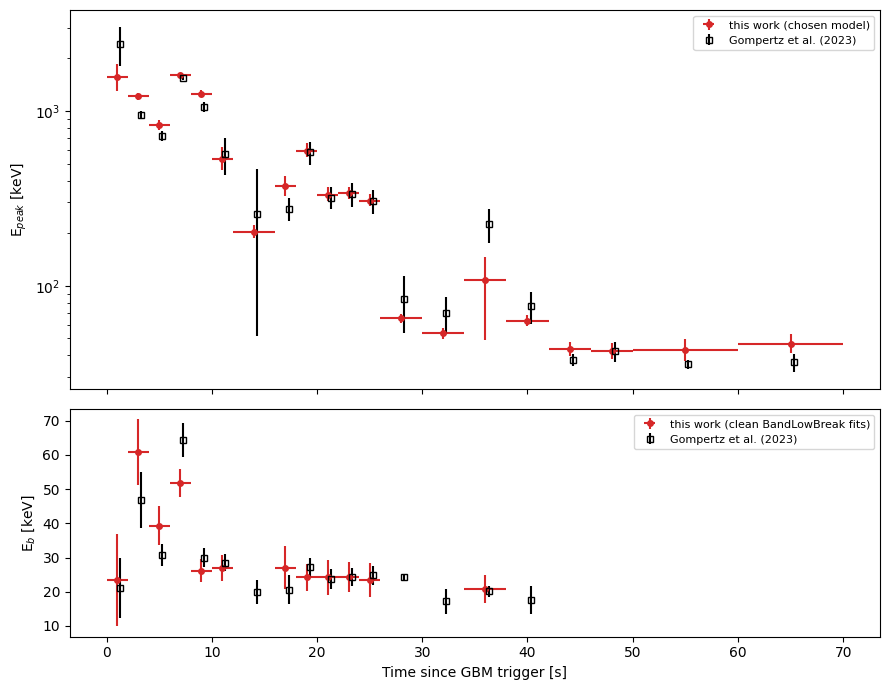

,model,Epeak,Epeak_err,G_Ep,G_Ep_err,Epeak_sigma,Epeak_lowbreak,Eb,Eb_err,G_Eb,G_Eb_err,alpha1,G_alpha1,alpha2,G_alpha2,Eb_sigma
label,,,,,,,,,,,,,,,,
g00_02,BandLowBreak,1565.83,271.40,2411.3,602.00,-1.28,1565.83,23.31,13.43,21.0,8.8,-0.74,-0.69,-1.38,-1.50,0.14
g02_04,BandLowBreak,1212.14,55.91,951.6,47.40,3.55,1212.14,60.79,9.53,46.7,8.2,-0.63,-0.54,-1.33,-1.40,1.12
g04_06,BandLowBreak,828.51,55.96,721.0,47.50,1.46,828.51,39.32,5.69,30.7,3.3,-0.57,-0.39,-1.42,-1.49,1.31
g06_08,BandLowBreak,1606.91,37.14,1543.0,47.50,1.06,1606.91,51.77,3.97,64.3,4.9,-0.37,-0.48,-1.29,-1.44,-1.99
g08_10,BandLowBreak,1257.74,59.44,1053.6,72.00,2.19,1257.74,26.15,3.43,30.0,2.7,-0.16,-0.33,-1.44,-1.49,-0.88
g10_12,BandLowBreak,532.93,80.80,567.1,135.70,-0.22,532.93,27.01,3.74,28.5,2.4,-0.15,-0.31,-1.82,-1.78,-0.34
g12_16,Comptonized,203.35,17.32,257.3,205.70,-0.26,249.03,NaN,NaN,19.9,3.6,NaN,-0.27,NaN,-1.84,NaN
g16_18,BandLowBreak,370.70,47.70,275.0,40.90,1.52,370.70,27.05,6.34,20.6,4.2,-0.50,-0.35,-1.69,-1.64,0.85
g18_20,BandLowBreak,593.14,55.69,580.0,86.50,0.13,593.14,24.23,4.01,27.2,2.8,-0.19,-0.39,-1.65,-1.68,-0.61


In [11]:
# Gompertz et al. (2023) Table 1: 2SBPL up to 42 s (alpha1, Eb, alpha2, Ep, beta), Band after (alpha, Ep, beta)
GOMPERTZ = pd.DataFrame([
    ("g00_02", 0.69, 0.32, 21.0, 8.8, 1.50, 0.06, 2411.3, 602.0, 4.74, 1.87),
    ("g02_04", 0.54, 0.07, 46.7, 8.2, 1.40, 0.04, 951.6, 47.4, 2.74, 0.08),
    ("g04_06", 0.39, 0.10, 30.7, 3.3, 1.49, 0.03, 721.0, 47.5, 2.89, 0.11),
    ("g06_08", 0.48, 0.03, 64.3, 4.9, 1.44, 0.02, 1543.0, 47.5, 3.09, 0.07),
    ("g08_10", 0.33, 0.09, 30.0, 2.7, 1.49, 0.02, 1053.6, 72.0, 2.90, 0.12),
    ("g10_12", 0.31, 0.12, 28.5, 2.4, 1.78, 0.04, 567.1, 135.7, 2.99, 0.36),
    ("g12_16", 0.27, 0.37, 19.9, 3.6, 1.84, 0.29, 257.3, 205.7, 2.29, 0.52),
    ("g16_18", 0.35, 0.25, 20.6, 4.2, 1.64, 0.09, 275.0, 40.9, 2.74, 0.23),
    ("g18_20", 0.39, 0.12, 27.2, 2.8, 1.68, 0.04, 580.0, 86.5, 3.02, 0.28),
    ("g20_22", 0.30, 0.16, 23.8, 2.9, 1.69, 0.06, 319.6, 45.8, 2.89, 0.25),
    ("g22_24", 0.35, 0.14, 24.2, 2.6, 1.73, 0.05, 335.2, 51.5, 3.04, 0.30),
    ("g24_26", 0.34, 0.14, 24.8, 2.7, 1.75, 0.05, 305.5, 47.9, 3.01, 0.29),
    ("g26_30", 0.49, 0.09, 24.3, 0.9, 1.98, 0.02, 83.9, 30.3, 3.26, 0.67),
    ("g30_34", 0.18, 0.46, 17.2, 3.7, 1.85, 0.24, 69.8, 16.9, 2.61, 0.39),
    ("g34_38", 0.19, 0.18, 20.2, 1.6, 1.89, 0.04, 225.6, 50.9, 3.99, 0.73),
    ("g38_42", 0.23, 0.47, 17.6, 4.2, 1.85, 0.25, 76.3, 15.9, 2.64, 0.42),
    ("g42_46", 0.67, 0.39, np.nan, np.nan, np.nan, np.nan, 37.7, 3.06, 2.23, 0.05),
    ("g46_50", 0.67, 0.47, np.nan, np.nan, np.nan, np.nan, 42.2, 5.61, 2.14, 0.05),
    ("g50_60", 0.85, 0.19, np.nan, np.nan, np.nan, np.nan, 35.5, 2.29, 2.24, 0.05),
    ("g60_70", 0.92, 0.35, np.nan, np.nan, np.nan, np.nan, 36.4, 4.32, 2.18, 0.08),
], columns=["label", "alpha1", "alpha1_err", "Eb", "Eb_err", "alpha2", "alpha2_err", "Ep", "Ep_err",
            "beta", "beta_err"]).set_index("label")
for col in ("alpha1", "alpha2", "beta"):
    GOMPERTZ[col] = -GOMPERTZ[col]
assert list(GOMPERTZ.index) == [l for l in WIN if l.startswith("g")]

r = results.loc[GOMPERTZ.index]
my_err = 0.5 * (r.Epeak_err_lo + r.Epeak_err_hi)
compare = pd.DataFrame({"model": r.model, "Epeak": r.Epeak, "Epeak_err": my_err, "G_Ep": GOMPERTZ.Ep,
                        "G_Ep_err": GOMPERTZ.Ep_err, "Epeak_sigma": (r.Epeak - GOMPERTZ.Ep) / np.hypot(my_err, GOMPERTZ.Ep_err),
                        "Epeak_lowbreak": r.Epeak_lowbreak,
                        "Eb": r.Eb.where(r.lowbreak_clean), "Eb_err": r.Eb_err.where(r.lowbreak_clean),
                        "G_Eb": GOMPERTZ.Eb, "G_Eb_err": GOMPERTZ.Eb_err,
                        "alpha1": r.alpha1_lb.where(r.lowbreak_clean), "G_alpha1": GOMPERTZ.alpha1,
                        "alpha2": r.alpha2_lb.where(r.lowbreak_clean), "G_alpha2": GOMPERTZ.alpha2})
compare["Eb_sigma"] = (compare.Eb - compare.G_Eb) / np.hypot(compare.Eb_err, compare.G_Eb_err)
within = (compare.Epeak_sigma.abs() < 2).sum()
print(f"E_peak within 2 sigma of Gompertz in {within} of {len(compare)} slices; "
      f"median ratio mine/theirs {np.median(compare.Epeak / compare.G_Ep):.2f}")
clean = compare.Eb.notna() & compare.G_Eb.notna()
print(f"slices where both have a low-energy break: {clean.sum()}; E_b within 2 sigma in "
      f"{(compare.Eb_sigma[clean].abs() < 2).sum()}")

mid = 0.5 * (windows.loc[GOMPERTZ.index, "t_start"] + windows.loc[GOMPERTZ.index, "t_stop"])
half = 0.5 * (windows.loc[GOMPERTZ.index, "t_stop"] - windows.loc[GOMPERTZ.index, "t_start"])
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1.2]})
axes[0].errorbar(mid, compare.Epeak, xerr=half, yerr=[r.Epeak_err_lo, r.Epeak_err_hi], fmt="o", ms=4, color="tab:red",
                 label="this work (chosen model)")
axes[0].errorbar(mid + 0.3, compare.G_Ep, yerr=compare.G_Ep_err, fmt="s", ms=4, mfc="none", color="black",
                 label="Gompertz et al. (2023)")
axes[0].set(yscale="log", ylabel="E$_{peak}$ [keV]")
axes[0].legend(fontsize=8)
axes[1].errorbar(mid, compare.Eb, xerr=half, yerr=compare.Eb_err, fmt="o", ms=4, color="tab:red",
                 label="this work (clean BandLowBreak fits)")
axes[1].errorbar(mid + 0.3, compare.G_Eb, yerr=compare.G_Eb_err, fmt="s", ms=4, mfc="none", color="black",
                 label="Gompertz et al. (2023)")
axes[1].set(ylabel="E$_b$ [keV]", xlabel="Time since GBM trigger [s]")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(S.FIGURE_DIR / "14_gompertz_comparison.png", dpi=200)
plt.show()
compare.round(2)

Slice by slice my E_peak is within 2 sigma of Gompertz's in 18 of the 20 slices, with a median ratio of 1.02. The two
exceptions are 2-4 s and 8-10 s, where mine is 20-27% higher (3.6 sigma and 2.2 sigma); there E_peak is above 1 MeV and
set mostly by the BGO, which we select differently (from 200 keV here, from 300 keV in their fits). The
low-energy break agrees within 2 sigma in all 12 slices where we both find one, between 20 and 64 keV, and the slopes
agree too (alpha1 -0.15 to -0.74 here against -0.19 to -0.69 in their fits; alpha2 -1.29 to -1.91 against -1.40 to
-1.89). Their E_b falls from ~65 keV at 6-8 s to ~20 keV by 34-38 s, and mine follows it.

This is an independent check: different software (GDT, not XSPEC), GBM only (no BAT), my own background, and my
own two-break model with a fixed smoothness, and it gives the same breaks. It also means the method that finds
the drifting break in GRB 230307A (notebook 12) recovers a published one here, where two NaI detectors see the
low energies.

## 8. E_peak(t) of both bursts

As in the bottom panel of Dichiara's Fig. 2 (GRB 230307A from `shared/epeak_230307A.csv`). For GRB 211211A the
filled marker shows which model gives E_peak, and the open circles are Band's E_peak in every window, the same
model as the GRB 230307A points, so that the two bursts can also be compared like for like. The dotted lines
are Troja et al.'s three values over the windows above.

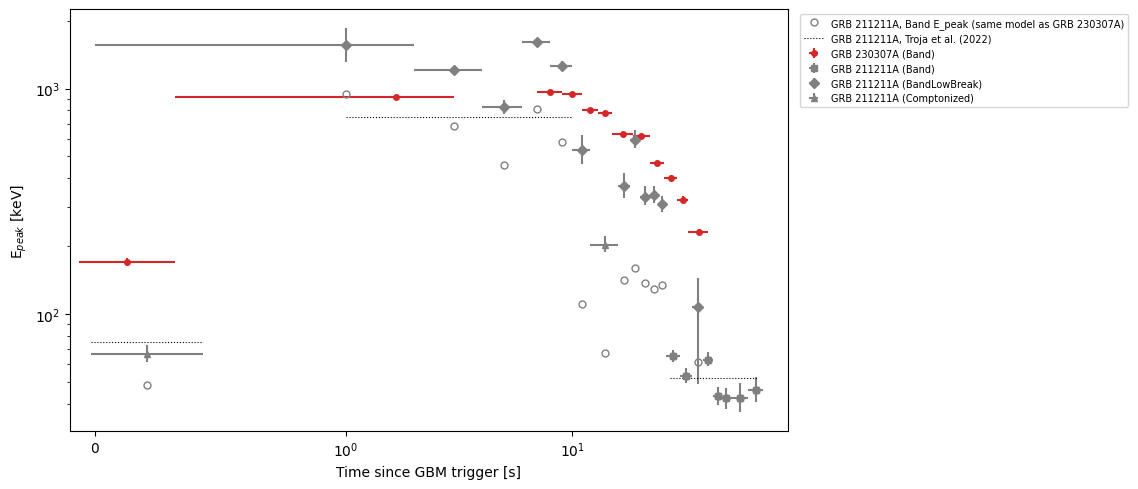

In [12]:
other = pd.read_csv(S.CODE_DIR / "shared" / "epeak_230307A.csv").set_index("label")
other = other[other.dichiara_table.str.contains("2")]
mine = windows.join(results)
mine = mine[~mine.index.str.startswith("f2_")]

fig, ax = plt.subplots(figsize=(11.5, 5))
ax.errorbar(0.5 * (other.t_start + other.t_stop), other.Epeak_keV, xerr=0.5 * (other.t_stop - other.t_start),
            yerr=[np.hypot(other.Epeak_err_lo, other.Epeak_sys), np.hypot(other.Epeak_err_hi, other.Epeak_sys)],
            fmt="o", ms=4, color="tab:red", label="GRB 230307A (Band)")
for model, marker in (("Band", "s"), ("BandLowBreak", "D"), ("Comptonized", "^")):
    m = mine[mine.model == model]
    if len(m):
        ax.errorbar(0.5 * (m.t_start + m.t_stop), m.Epeak, xerr=0.5 * (m.t_stop - m.t_start),
                    yerr=[m.Epeak_err_lo.fillna(0), m.Epeak_err_hi.fillna(0)], fmt=marker, ms=5, color="grey",
                    label=f"GRB 211211A ({model})")
ax.plot(0.5 * (mine.t_start + mine.t_stop), mine.Epeak_band, "o", mfc="none", color="grey", ms=5,
        label="GRB 211211A, Band E_peak (same model as GRB 230307A)")
for label, value in TROJA.troja_Epeak.items():
    t0, t1 = WIN[label]
    ax.plot([t0, t1], [value, value], color="black", lw=0.8, ls=":")
ax.plot([], [], color="black", lw=0.8, ls=":", label="GRB 211211A, Troja et al. (2022)")
ax.set(yscale="log", xlabel="Time since GBM trigger [s]", ylabel="E$_{peak}$ [keV]")
ax.set_xscale("symlog", linthresh=1.0)
ax.set_xlim(-0.1, 90)
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
fig.savefig(S.FIGURE_DIR / "14_epeak_time_both_bursts.png", dpi=200, bbox_inches="tight")
plt.show()

With the same model, Band (open circles against red), GRB 211211A's E_peak is below GRB 230307A's at almost every
time after the first few seconds, and both fall with time. With the best model (filled grey) the first 10 s of
GRB 211211A peak at 0.8-1.6 MeV, against ~0.9-1 MeV for GRB 230307A. The precursors differ most: 67 keV for GRB
211211A against 170 keV for GRB 230307A, both far below their main emission, with similar MVT (21 and 17 ms, from
Troja et al. and Dichiara et al.).

## 9. Results table

Same columns as `shared/epeak_230307A.csv` (described in `shared/README.md`), written to
`shared/epeak_211211A.csv`. The `model` column says which model gives E_peak in each window, and the notes say
why. Here the alpha and beta errors are from the covariance matrix (symmetric), and the systematic and rest-frame
columns are left empty: I haven't run the systematics for this burst.

In [13]:
def git(*args):
    return subprocess.run(["git", *args], cwd=S.CODE_DIR, capture_output=True, text=True).stdout.strip()

commit = git("rev-parse", "--short", "HEAD") + ("+uncommitted" if git("status", "--porcelain", ".") else "")
t = windows.join(results)

def notes_for(label):
    r = t.loc[label]
    notes = [f"window: {r.source}"]
    if r.beta_band > -2.01:
        notes.append(f"Band beta at its -2 limit, so Band's E_peak ({r.Epeak_band:.0f} keV) is a break, not the peak")
    if r.model == "BandLowBreak":
        notes.append(f"two-break fit, Delta C {r.dC_band_minus_lowbreak:.0f} over Band: break at {r.Eb:.0f} keV, alpha1 "
                     f"{r.alpha1_lb:.2f} below it, alpha2 {r.alpha2_lb:.2f} above; Band's E_peak is {r.Epeak_band:.0f} keV")
    if r.model == "Comptonized":
        notes.append(f"Band tail not needed (Delta C {r.dC_cpl_minus_band:.1f}), E_peak from Comptonized")
    if r.model != "Comptonized" and r.beta_err > 1:
        notes.append("beta not constrained: no measurable tail above the peak")
    if response_type["n2", label] != "single DRM":
        notes.append("counts-weighted response (crosses a DRM boundary)")
    return "; ".join(notes)

table = pd.DataFrame({
    "label": t.index, "t_start": t.t_start.values, "t_stop": t.t_stop.values, "dichiara_table": "",
    "model": t.model.values, "Epeak_keV": t.Epeak.values, "Epeak_err_lo": t.Epeak_err_lo.values,
    "Epeak_err_hi": t.Epeak_err_hi.values, "Epeak_sys": np.nan, "Epeak_NaI40_keV": np.nan,
    "alpha": t.alpha.values, "alpha_err_lo": t.alpha_err.values, "alpha_err_hi": t.alpha_err.values, "alpha_sys": np.nan,
    "beta": t.beta.values, "beta_err_lo": t.beta_err.values, "beta_err_hi": t.beta_err.values, "beta_upper95": np.nan,
    "flux_10_1000keV_erg_cm2_s": t.flux.values * 1e-5, "flux_err": t.flux_err.values * 1e-5,
    "cstat": t.cstat.values, "dof": t.dof.values, "Epeak_cpl_keV": t.Epeak_cpl.values,
    "dC_cpl_minus_band": t.dC_cpl_minus_band.values, "Epeak_rest_keV": np.nan, "notes": [notes_for(l) for l in t.index],
    "notebook": "14_grb211211a.ipynb", "commit": commit, "run_date": date.today().isoformat()})
check = pd.read_csv(S.CODE_DIR / "shared" / "epeak_230307A.csv", nrows=1)
assert list(table.columns) == list(check.columns)
table.to_csv(S.CODE_DIR / "shared" / "epeak_211211A.csv", index=False, float_format="%.6g")
print(f"wrote {len(table)} windows, commit {commit}")

wrote 23 windows, commit a2061d8+uncommitted
